# ProcuraAI - Complete Implementation (Google Colab)
**An LLM-powered invoice and procurement compliance auditor** - synthetic data, OCR, structured extraction, RAG with citations, a LangGraph multi-agent workflow, a deterministic `Decimal` audit engine, reports, FastAPI, Streamlit, tests and evaluation.

* **Run the sections in order.** Each section: purpose -> code -> a validation printout.
* **Everything is synthetic and fictional.** Tax rates/policies are synthetic configuration, not Pakistani tax law.
* **No API key is needed** except for the optional Gemini features (marked). Without a key the notebook falls back to rule-based extraction and template explanations and says so.
* The audit package (`src/procuraai`) has no Colab dependency; this notebook is only a driver. It never approves payments - all payment decisions stay with humans.
* Colab-hosted API/dashboard URLs are temporary and are not production infrastructure.

## Section 0 - Load the project source
The notebook embeds the full repository (source, tests, scripts, docs) as a compressed archive so it works without cloning. If you have published the repo you can instead `git clone` it and skip this cell.

*Generated files:* `procuraai-invoice-auditor/` under the work directory. *External dependency:* none.

In [ ]:
import base64, io, os, sys, zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
WORK = Path("/content") if IN_COLAB else Path.cwd() / "colab_run"
WORK.mkdir(parents=True, exist_ok=True)
PROJECT = WORK / "procuraai-invoice-auditor"
BUNDLE_B64 = "..."
with zipfile.ZipFile(io.BytesIO(base64.b64decode(BUNDLE_B64))) as z:
    z.extractall(PROJECT)
sys.path.insert(0, str(PROJECT / "src"))
os.chdir(PROJECT)
print("IN_COLAB:", IN_COLAB, "| project:", PROJECT)
print("files extracted:", sum(1 for _ in PROJECT.rglob("*") if _.is_file()))
assert (PROJECT / "src/procuraai/audit/engine.py").exists()

## Section 1 - Environment setup
Installs compatible libraries (Colab already ships pandas, numpy, scikit-learn, Pillow, openpyxl), installs the Tesseract OCR binary if missing, prints versions, sets seeds, detects Google Drive and creates project directories with a local fallback.

*External/system dependencies:* PyPI, and `apt` for Tesseract.

In [ ]:
import subprocess, shutil, importlib, random, platform
import numpy as np

pkgs = ["pymupdf", "pydantic>=2.5", "rapidfuzz", "reportlab", "faiss-cpu", "langgraph", "fastapi", "uvicorn", "sqlalchemy",
        "python-multipart", "httpx", "pytest", "pytesseract", "google-genai", "streamlit", "matplotlib"]
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], capture_output=True, text=True)
print("pip exit code:", r.returncode, r.stderr[-300:] if r.returncode else "")
if shutil.which("tesseract") is None:
    subprocess.run(["apt-get", "install", "-y", "-qq", "tesseract-ocr"], capture_output=True)
print("tesseract:", shutil.which("tesseract") or "NOT FOUND (OCR documents will fail; text PDFs still work)")

SEED = 20250101
random.seed(SEED); np.random.seed(SEED)

for m in ["pandas", "pydantic", "pymupdf", "PIL", "rapidfuzz", "faiss", "langgraph", "fastapi", "sqlalchemy", "pytest", "pytesseract", "streamlit"]:
    try:
        mod = importlib.import_module(m)
        print(f"{m:12s}", getattr(mod, "__version__", getattr(mod, "VERSION", "ok")))
    except Exception as e:
        print(f"{m:12s} MISSING ({type(e).__name__})")
print("python", platform.python_version())

# Google Drive (optional) with a local fallback
DATA_ROOT = WORK
DRIVE_MOUNTED = False
if IN_COLAB:
    try:
        from google.colab import drive
        if not Path("/content/drive/MyDrive").exists():
            drive.mount("/content/drive")      # set to a comment to skip Drive
        DRIVE_MOUNTED = Path("/content/drive/MyDrive").exists()
    except Exception as e:
        print("Drive not mounted:", type(e).__name__)
if DRIVE_MOUNTED:
    DATA_ROOT = Path("/content/drive/MyDrive/ProcuraAI"); DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("Drive mounted:", DRIVE_MOUNTED, "| data root:", DATA_ROOT)
DATA = DATA_ROOT / "procuraai-data"
OUT = DATA_ROOT / "outputs"; OUT.mkdir(parents=True, exist_ok=True)


In [ ]:
# validation
import procuraai
from procuraai import __version__
print("procuraai", __version__, "imported OK; data dir:", DATA)

## Section 2 - Configuration and security
`GEMINI_API_KEY` is read from **Colab Secrets** (left sidebar -> key icon -> add `GEMINI_API_KEY`, enable notebook access) or an environment variable. The key is never printed, logged, written to datasets/reports or committed.

| Needs the Gemini key | Works without it |
|---|---|
| LLM field extraction (`extraction_mode="llm"/"auto"`), LLM explanations | Dataset generator, OCR, rule-based extraction, matching, RAG, audit engine, agents, API, dashboard, tests |

If a Gemini call fails the code raises/records a clear error and falls back - it never silently pretends the LLM succeeded.

In [4]:
def get_secret(name):
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v: return v
    except Exception:
        pass
    return os.environ.get(name)

_key = get_secret("GEMINI_API_KEY")
if _key:
    os.environ["GEMINI_API_KEY"] = _key
del _key

from procuraai.config import Settings
settings = Settings()
print(settings.redacted())                    # redacted: only shows <set> / <not set>
print("\nGemini key configured:", bool(settings.gemini_api_key))
if not settings.gemini_api_key:
    print("-> LLM features disabled; rule-based extraction + template explanations will be used (and reported as such).")

{'gemini_api_key': '<not set>', 'gemini_model': 'gemini-2.5-flash', 'embedding_model': 'sentence-transformers/all-MiniLM-L6-v2', 'data_dir': 'procuraai-data', 'db_url': 'sqlite:///procuraai.db', 'upload_dir': 'uploads', 'api_key': '<not set>', 'max_upload_mb': '25', 'llm_timeout_s': '60.0', 'llm_max_retries': '3'}

Gemini key configured: False
-> LLM features disabled; rule-based extraction + template explanations will be used (and reported as such).


## Section 3 - Synthetic data generation
Generates the full fictional Pakistan-based procurement dataset with a **fixed seed**: 8 suppliers, 52 products, 10 pricing agreements, 72 invoices, 65 POs, 68 delivery records, contracts and policies, selectable-text PDFs, image-only PDFs, PNG/JPG images with degradation, text invoices, CSVs, an Excel workbook, a manifest and **ground truth** (kept in separate files, never given to the agents).

Cross-document references are validated **before** saving; generation stops with a clear error if anything is inconsistent.

*Generated files:* `procuraai-data/` and `procuraai_synthetic_dataset.zip`.

In [ ]:
import time
from procuraai.datagen.catalog import ELECTRICAL_PKR
from procuraai.datagen.generator import generate
from procuraai.datagen.export import write_dataset, DatasetIntegrityError

t0 = time.time()
ds = generate(ELECTRICAL_PKR, seed=SEED)
try:
    info = write_dataset(ds, DATA)          # runs validate_dataset() first
except DatasetIntegrityError as e:
    raise SystemExit(str(e))
print("generated in %.1fs" % (time.time() - t0))
print(info["stats"]); print("zip:", info["zip"], info["zip_mb"], "MB")

In [6]:
# Dataset inventory + validation
import pandas as pd, collections
inv = collections.Counter()
for p in DATA.rglob("*"):
    if p.is_file():
        inv[("/".join(p.relative_to(DATA).parts[:-1]), p.suffix.lower())] += 1
print(pd.Series(inv).rename("files").to_frame().to_string())
gt = pd.read_csv(DATA / "ground_truth/ground_truth.csv")
print("\nground-truth rows:", len(gt), "| invoices:", gt.invoice_id.nunique(), "| scenarios covered:", sorted(gt.scenario_no.unique()))
print(gt.anomaly_code.value_counts().to_string())

                                    files
                             .txt       1
ground_truth                 .csv       2
                             .txt       1
manifest                     .csv       1
                             .txt       1
                             .json      1
structured                   .csv       9
                             .xlsx      1
raw/policies                 .pdf       5
                             .md        1
                             .txt       5
raw/contracts                .pdf       8
                             .txt       8
raw/invoices/text            .txt       5
raw/invoices/images          .png      11
                             .jpg       6
raw/invoices/pdf             .pdf      50
raw/delivery_challans/images .jpg       5
                             .png       4
raw/delivery_challans/pdf    .pdf      59
raw/purchase_orders/images   .png       4
                             .jpg       4
raw/purchase_orders/pdf      .pdf 

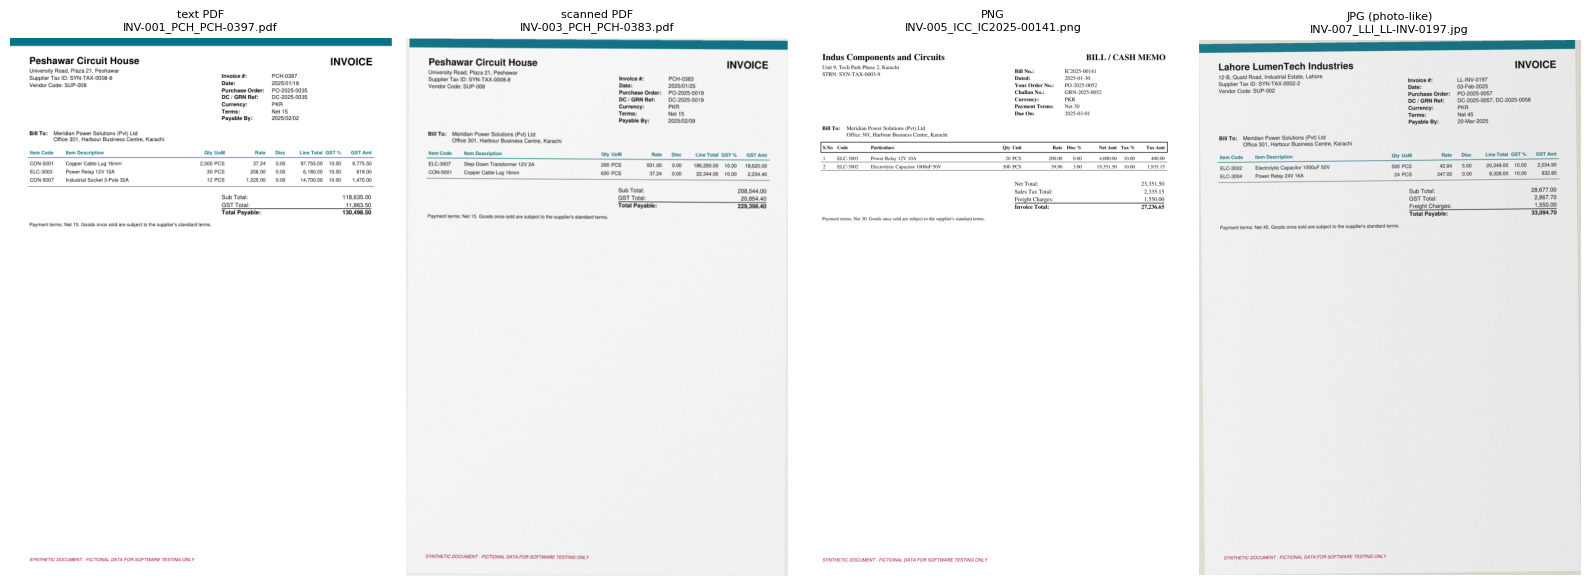

In [7]:
# Previews: selectable-text PDF, scanned (image-only) PDF, degraded PNG, photographed JPG
import pymupdf, matplotlib
try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except Exception:
    pass
import matplotlib.pyplot as plt
from PIL import Image
raw = DATA / "raw"
def first_page(path):
    if path.suffix == ".pdf":
        d = pymupdf.open(path); pix = d[0].get_pixmap(dpi=70); return Image.frombytes("RGB", (pix.width, pix.height), pix.samples)
    return Image.open(path).convert("RGB")
text_pdf = next(p for p in sorted((raw/"invoices/pdf").glob("*.pdf")) if pymupdf.open(p)[0].get_text().strip())
scan_pdf = next(p for p in sorted((raw/"invoices/pdf").glob("*.pdf")) if not pymupdf.open(p)[0].get_text().strip())
png = sorted((raw/"invoices/images").glob("*.png"))[0]; jpg = sorted((raw/"invoices/images").glob("*.jpg"))[0]
fig, ax = plt.subplots(1, 4, figsize=(16, 6))
for a, (t, p) in zip(ax, [("text PDF", text_pdf), ("scanned PDF", scan_pdf), ("PNG", png), ("JPG (photo-like)", jpg)]):
    a.imshow(first_page(p)); a.set_title(f"{t}\n{p.name}", fontsize=8); a.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# Download the archive (Colab only) - guarded so the notebook also runs elsewhere
try:
    from google.colab import files
    files.download(info["zip"])
except Exception:
    print("Not in Colab (or download blocked). Archive is at:", info["zip"])

## Section 4 - Document ingestion
Supports PDF (PyMuPDF text layer), PNG/JPG (Tesseract OCR), CSV, XLSX, TXT/MD, batches and nested ZIPs, with extension/size/zip-slip validation. **OCR is applied only to pages without usable text** - never blindly. Each document keeps its source filename, page number, detected type and extraction confidence.

In [9]:
from procuraai.ingestion.loader import load_file, ingest_paths, detect_doc_type
samples = [text_pdf, scan_pdf, png, next((raw/"invoices/text").glob("*.txt")), next((raw/"purchase_orders/pdf").glob("*.pdf")), next((raw/"delivery_challans/pdf").glob("*.pdf"))]
rows = []
for p in samples:
    t0 = time.time(); d = load_file(p)
    rows.append(dict(file=p.name, type=d.doc_type, text_method=d.method, confidence=round(d.confidence, 2), pages=len(d.pages), chars=len(d.text), seconds=round(time.time()-t0, 2)))
print(pd.DataFrame(rows).to_string(index=False))
assert rows[0]["text_method"] == "text-layer" and rows[1]["text_method"] == "ocr"      # OCR only where needed
print("\nreconstructed lines of the scanned PDF (OCR):\n", load_file(scan_pdf).text[:600])

                        file             type text_method  confidence  pages  chars  seconds
    INV-001_PCH_PCH-0397.pdf          INVOICE  text-layer        1.00      1    910     0.00
    INV-003_PCH_PCH-0383.pdf          INVOICE         ocr        0.88      1    858     2.93
INV-005_ICC_IC2025-00141.png          INVOICE         ocr        0.93      1    783     1.62
   INV-068_SCW_SCW-00203.txt          INVOICE  plain-text        1.00      1    826     0.00
            PO-2025-0002.pdf   PURCHASE_ORDER  text-layer        1.00      1    662     0.00
            DC-2025-0067.pdf DELIVERY_CHALLAN  text-layer        1.00      1    432     0.00



reconstructed lines of the scanned PDF (OCR):
 Peshawar Circuit House
INVOICE
University Road, Plaza 21, Peshawar
Supplier Tax ID: SYN-TAX-0008-8  Invoice f  #:  PCH-0383
Vendor Code: SUP-008  Date:  2025/01/25
Purchase Order:  PO-2025-0019
DC / GRN Ref:  DC-2025-0019
Currency:  PKR
Terms:  Net 15
Payable By:  2025/02/09
Bill To:  Meridian Power Solutions (Pvt) Ltd
Office 301, Harbour Business Centre, Karachi
Item Code  Item Description  Qty UoM  Rate  Disc  Line Total GST %  GST Amt
OO EE  ee
ELC-3007  Step-Down Transformer 12V 2A  200 PCS  931.00  0.00  186,200.00  10.00  18,620.00
CON-5001  Copper Cable Lug 16mm  600 PCS  37.24  0.00  2


In [ ]:
# Batch ingestion with errors (one bad file never stops the batch) + upload interface
bad_dir = WORK / "bad_inputs"; bad_dir.mkdir(exist_ok=True)
(bad_dir / "empty.pdf").write_bytes(b""); (bad_dir / "corrupt.pdf").write_bytes(b"%PDF-1.4 not really"); (bad_dir / "tool.exe").write_bytes(b"MZ")
docs, errors = ingest_paths([bad_dir/"empty.pdf", bad_dir/"corrupt.pdf", bad_dir/"tool.exe", text_pdf], workdir=WORK/"unzipped")
print("ingested:", [d.source_file for d in docs]); print("errors:", errors)

UPLOADED = []
def upload_documents():
    """Colab upload widget: files are saved under WORK/uploads and returned as paths (PDF, images, TXT, CSV/XLSX, ZIP)."""
    from google.colab import files
    up = files.upload(); dest = WORK / "uploads"; dest.mkdir(exist_ok=True); out = []
    for name, data in up.items():
        p = dest / Path(name).name; p.write_bytes(data); out.append(p)
    return out
# UPLOADED = upload_documents()     # <- uncomment in Colab to audit your own (synthetic/test) documents in Section 8

## Section 5 - Structured extraction
Pydantic schemas (`procuraai.schemas`) cover suppliers, invoice headers/lines/charges, POs, delivery records, agreements, policies and findings. Unknown values stay `None` and are listed in `missing_fields`; per-field **provenance** (file, page, excerpt, method, confidence) is stored.

Extractors: **rule-based/template** (offline) and **Gemini** (schema-constrained JSON, Pydantic re-validation, bounded retries, explicit errors). For scans, OCR is retried with other preprocessing and the pass whose result is most *self-consistent* (lines sum to subtotal, totals foot) is kept.

In [11]:
from procuraai.extraction.pipeline import extract_file
from procuraai.extraction.structured import load_structured_dir
S = load_structured_dir(DATA / "structured")                 # observed structured values (no labels)
truth = {i.source_file: i for i in S["invoices"]}
doc, rec = extract_file(text_pdf)
print(rec.model_dump_json(indent=1, include={"invoice_number","invoice_date","supplier_name","po_number","currency","subtotal","tax_total","grand_total","missing_fields","extraction_confidence"}))
print("\nline 1:", rec.lines[0].model_dump(include={"product_code","description","quantity","unit_price","discount_pct","line_amount","tax_rate","tax_amount"}))
print("\nprovenance[invoice_number]:", rec.provenance["invoice_number"].model_dump())
t = truth[text_pdf.name]
assert (rec.invoice_number, rec.grand_total, len(rec.lines)) == (t.invoice_number, t.grand_total, len(t.lines))
print("matches the structured record: OK")

{
 "extraction_confidence": 1.0,
 "missing_fields": [],
 "invoice_number": "PCH-0397",
 "invoice_date": "2025-01-18",
 "supplier_name": "Peshawar Circuit House",
 "po_number": "PO-2025-0035",
 "currency": "PKR",
 "subtotal": "118635.00",
 "tax_total": "11863.50",
 "grand_total": "130498.50"
}

line 1: {'product_code': 'CON-5001', 'description': 'Copper Cable Lug 16mm', 'quantity': '2500', 'unit_price': '37.24', 'discount_pct': '0.00', 'line_amount': '97755.00', 'tax_rate': '10.00', 'tax_amount': '9775.50'}

provenance[invoice_number]: {'source_file': 'INV-001_PCH_PCH-0397.pdf', 'page': 1, 'excerpt': 'Supplier Tax ID: SYN-TAX-0008-8  Invoice #:  PCH-0397', 'method': 'rule', 'confidence': 1.0}
matches the structured record: OK


In [12]:
# Extraction accuracy on a sample (full-dataset numbers: Section 13 / docs/evaluation.md)
from procuraai import evaluation as E
sample = sorted((raw/"invoices/pdf").glob("*.pdf"))[:8] + sorted((raw/"invoices/images").glob("*.png"))[:3] + sorted((raw/"invoices/text").glob("*.txt"))[:2]
recs, methods = [], {}
for p in sample:
    d, r = extract_file(p); recs.append(r); methods[p.name] = "ocr" if "ocr" in d.method else "text-layer/plain"
res = E.evaluate_extraction(recs, S["invoices"], methods)
print({k: dict(docs=v["documents"], fully_correct=v["documents_fully_correct"], field_accuracy=v["field_accuracy"]) for k, v in res.items()})

{'ocr': {'docs': 4, 'fully_correct': 1, 'field_accuracy': 0.9712}, 'text-layer/plain': {'docs': 9, 'fully_correct': 9, 'field_accuracy': 1.0}}


In [13]:
# Gemini extraction (OPTIONAL - requires GEMINI_API_KEY). Errors are shown honestly; nothing is simulated.
from procuraai.extraction.llm import GeminiClient, extract_invoice_with_llm, LLMError, LLMUnavailable
gem = GeminiClient(settings.gemini_api_key, settings.gemini_model, settings.llm_timeout_s, settings.llm_max_retries)
print("Gemini available:", gem.available)
if gem.available:
    try:
        r = extract_invoice_with_llm(gem, load_file(text_pdf).text, text_pdf.name)
        print("LLM extraction:", r.invoice_number, r.grand_total, "confidence", r.extraction_confidence, "| usage:", gem.usage)
    except (LLMError, LLMUnavailable) as e:
        print("LLM extraction FAILED (rule-based extraction would be used):", e)
else:
    print("Skipped: no API key. Rule-based extraction is used everywhere else.")

Gemini available: False
Skipped: no API key. Rule-based extraction is used everywhere else.


## Section 6 - Normalization and entity matching
Normalizes supplier names, product codes, dates, currencies, units and money. Matching order: exact -> alias -> (tax id) -> fuzzy, with **configurable thresholds**. Low-confidence matches are never auto-accepted; they go to the human-review queue. Original and normalized values and candidates are retained in `MatchResult`.

In [14]:
from procuraai.normalization import SupplierMatcher, ProductMatcher, normalize_name, normalize_code, parse_date, invoice_key
from procuraai.config import AuditConfig
cfg = AuditConfig()                         # supplier_accept=90, supplier_review=75, product_accept=88, product_review=70, margin=6
sm = SupplierMatcher(S["suppliers"], cfg); pm = ProductMatcher(S["products"], cfg)
for name in ["Karachi Electro Traders (Pvt) Ltd", "KET Karachi", "Karachi Electro Trader Pvt Ltd", "Gwadar General Traders"]:
    m = sm.match(name); print(f"supplier {name!r:42} -> {m.matched_id} via {m.method} ({m.score:.0f}) review={m.needs_review}")
for code_, desc in [("ELE-1002", "Miniature Circuit Breaker 2-Pole 32A"), (None, "MCB 2P 32A"), (None, "Breaker Miniature Circuit 2-Pole 32A"),
                    (None, "Miniature Circuit Breaker 32A"), ("ELE-9901", "Hybrid Solar Inverter 5kW Single Phase")]:
    m = pm.match(code_, desc); print(f"product {str(code_)+' | '+desc!r:70} -> {m.matched_id} via {m.method} review={m.needs_review} candidates={[c.key for c in m.candidates[:2]]}")
print(parse_date("12-Mar-2025"), parse_date("12/03/2025"), normalize_code("ele 1001"), invoice_key("IC2025-00141") == invoice_key("1C2025-00141"))

supplier 'Karachi Electro Traders (Pvt) Ltd'        -> SUP-001 via exact (100) review=False
supplier 'KET Karachi'                              -> SUP-001 via alias (100) review=False
supplier 'Karachi Electro Trader Pvt Ltd'           -> SUP-001 via fuzzy (98) review=False
supplier 'Gwadar General Traders'                   -> None via none (62) review=False
product 'ELE-1002 | Miniature Circuit Breaker 2-Pole 32A'                      -> ELE-1002 via code_exact review=False candidates=[]
product 'None | MCB 2P 32A'                                                    -> ELE-1002 via alias review=False candidates=[]
product 'None | Breaker Miniature Circuit 2-Pole 32A'                          -> ELE-1002 via fuzzy review=False candidates=['ELE-1002', 'ELE-1003']
product 'None | Miniature Circuit Breaker 32A'                                 -> None via ambiguous review=True candidates=['ELE-1002', 'ELE-1003']
product 'ELE-9901 | Hybrid Solar Inverter 5kW Single Phase'                   

## Section 7 - RAG knowledge base
Loads supplier contracts, price lists and policies -> cleans -> **section-aware chunking** (configurable size/overlap; price schedules chunked by rows) -> embeddings -> **FAISS** index + **BM25** -> dense / keyword / **hybrid (RRF)** retrieval with supplier and doc-type filters. Every hit keeps filename, section/page, supplier and doc type. Evidence snippets are exact text from the source; `verify_citation` re-checks them. If nothing relevant exists the answer is *evidence not found* - never invented.

*Embeddings:* default is an **offline TF-IDF lexical baseline** (no download, no paid API). For local semantic embeddings install `sentence-transformers` and use `make_embedder(prefer_semantic=True)` (downloads a model from the Hugging Face hub on first use). Retrieved text is untrusted data.

In [15]:
from procuraai.services import load_services
svc = load_services(DATA)                      # master data + knowledge base (+ Gemini client only if a key exists)
print("\n".join(svc.notes)); kb = svc.kb
print("chunks:", len(kb.chunks))
for q, kw in [("Is freight or any additional charge allowed under this agreement?", dict(supplier_id="SUP-001")), ("What tax rate applies to cables?", {}), ("contract price of Miniature Circuit Breaker 2-Pole 32A", dict(supplier_id="SUP-001"))]:
    print("\nQ:", q)
    for h in kb.search(q, k=2, **kw):
        print(f"  #{h.rank} {h.chunk.source_file} | {h.chunk.section} | score {h.score:.3f}\n     {h.chunk.text[:140]!r}")
ev = kb.evidence_for("PRICE_ABOVE_CONTRACT", "SUP-001", "ELE-1002", agreement_id="AG-001-A")[0]
print("\nCited evidence:", ev.source_file, "|", ev.snippet, "| verified:", kb.verify_citation(ev))
print("No-evidence case ->", kb.evidence_for("NOT_A_REAL_CODE", "SUP-001"))

knowledge base: 122 chunks, embedder = tfidf-1-2gram (offline lexical baseline)
LLM: not configured (GEMINI_API_KEY not set) - rule-based extraction and template explanations are used
chunks: 122

Q: Is freight or any additional charge allowed under this agreement?
  #1 CONTRACT_SUP-001.txt | Freight and Additional Charges | score 0.267
     "[Freight and Additional Charges] Delivery to the Buyer's store is included in the unit prices. No freight, handling, packing, fuel or other "
  #2 POL-002.txt | Section 2.8 | score 0.153
     '[Section 2.8] Tax is calculated on the line amount after discount. Additional charges are not taxable under this synthetic policy.'

Q: What tax rate applies to cables?
  #1 POL-002.txt | Section 2.4 | score 0.324
     '[Section 2.4] Synthetic policy tax rate for Cables is 10 percent.'
  #2 POL-002.txt | Section 2.5 | score 0.171
     '[Section 2.5] Synthetic policy tax rate for Connectors is 10 percent.'

Q: contract price of Miniature Circuit Breaker 2-Pol

In [16]:
# Retrieval evaluation (Recall@k, MRR) - 14 policy Qs, 16 contract-clause Qs, 40 price-row lookups
rag = E.evaluate_rag(kb, svc.master)
print(pd.DataFrame({m: v["ALL"] for m, v in rag.items()}).T.to_string())
print("\nhybrid by query type:\n", pd.DataFrame(rag["hybrid"]).T.to_string())
assert rag["hybrid"]["ALL"]["recall@3"] >= 0.95

         recall@1  recall@3  recall@5     mrr     n
dense      0.9143       1.0       1.0  0.9548  70.0
keyword    0.9857       1.0       1.0  0.9929  70.0
hybrid     0.9857       1.0       1.0  0.9929  70.0

hybrid by query type:
                  recall@1  recall@3  recall@5     mrr     n
contract_clause    1.0000       1.0       1.0  1.0000  16.0
policy             0.9286       1.0       1.0  0.9643  14.0
price_row          1.0000       1.0       1.0  1.0000  40.0
ALL                0.9857       1.0       1.0  0.9929  70.0


## Section 8 - Multi-agent workflow (LangGraph)
Four explicit agents with data contracts on a shared `AuditState`:
1. **Document Intelligence** - ingest, OCR fallback, extract, validate, normalise.
2. **Procurement Evidence** - effective agreement/terms and RAG evidence with citations.
3. **Reconciliation & Audit** - deterministic three-way match and rule checks.
4. **Reporting & Review** - severity/confidence rules, explanations, exports, review queue.

Real LangGraph nodes, shared state, conditional routing (human-review node only when needed) and per-node error handling; a sequential fallback is used if LangGraph is missing. Deterministic Python is used wherever possible - no agent-to-agent LLM chatter. The human-review node only builds a queue: it triggers no action and no payment.

In [17]:
from procuraai.agents import run_audit, build_graph, HAVE_LANGGRAPH
print("LangGraph available:", HAVE_LANGGRAPH)
graph, _ = build_graph(svc)
try:
    print(graph.get_graph().draw_mermaid())
except Exception as e:
    print("(mermaid export unavailable:", type(e).__name__, ")")

LangGraph available: True
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	ingest(ingest)
	evidence(evidence)
	audit(audit)
	human_review(human_review)
	report(report)
	__end__([<p>__end__</p>]):::last
	__start__ --> ingest;
	audit -.-> human_review;
	audit -.-> report;
	evidence --> audit;
	human_review --> report;
	ingest -.-> evidence;
	ingest -.-> report;
	report --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [18]:
# A) Document path on a small, mixed batch: invoices (text PDF, scanned PDF, PNG, JPG, TXT) + the PO/DC files they reference
import re
pick = [text_pdf, scan_pdf, png, jpg, next((raw/"invoices/text").glob("*.txt"))]
paths = set(str(p) for p in pick)
for p in pick:
    i = truth[p.name]
    for sub in ("purchase_orders", "delivery_challans"):
        for f in (raw/sub).rglob("*.*"):
            refs = [i.po_number] + re.split(r"[,;]\s*", i.dc_reference or "")
            if f.stem in refs: paths.add(str(f))
state = run_audit(svc, input_mode="documents", paths=sorted(paths), extraction_mode="auto", outdir=str(OUT/"run_documents_demo"), workdir=str(WORK/"unz1"))
print("status:", state["status"], "| orchestrator:", state["timings"]["orchestrator"], "| timings:", state["timings"])
print(pd.DataFrame(state["report"]["metadata"]["extraction_log"])[["file","doc_type","method","confidence","seconds","llm_fallback"]].to_string(index=False))
print("\nsummary:", {k: v for k, v in state["report"]["summary"].items() if k.startswith("invoices_") or k.startswith("estimated")})

status: completed | orchestrator: langgraph | timings: {'document_intelligence_s': 31.38, 'procurement_evidence_s': 0.002, 'reconciliation_audit_s': 0.005, 'reporting_review_s': 0.0, 'total_s': 31.427, 'orchestrator': 'langgraph'}
                        file         doc_type   method  confidence  seconds                                   llm_fallback
           GRN-2025-0052.jpg DELIVERY_CHALLAN ocr+rule       0.948    7.736                                            NaN
            DC-2025-0019.pdf DELIVERY_CHALLAN     rule       1.000    0.007                                            NaN
            DC-2025-0035.pdf DELIVERY_CHALLAN     rule       1.000    0.007                                            NaN
            DC-2025-0057.pdf DELIVERY_CHALLAN     rule       1.000    0.006                                            NaN
            DC-2025-0058.pdf DELIVERY_CHALLAN     rule       1.000    0.007                                            NaN
           GRN-2025-0036.pdf DE

In [19]:
# B) Structured path over the whole dataset (all 72 invoices) - used for the metrics below
state_full = run_audit(svc, input_mode="structured", structured_dir=str(DATA/"structured"), outdir=str(OUT/"run_structured"))
print("status:", state_full["status"], "| total seconds:", state_full["timings"]["total_s"])
s = state_full["report"]["summary"]
print({k: s[k] for k in ["invoices_processed","invoices_passed","invoices_flagged","invoices_manual_review","human_review_pending","estimated_exposure_confirmed","estimated_exposure_potential","estimated_exposure_total"]})
print("review queue size:", len(state_full["review_queue"]))

status: completed | total seconds: 0.47
{'invoices_processed': 72, 'invoices_passed': 30, 'invoices_flagged': 32, 'invoices_manual_review': 10, 'human_review_pending': 42, 'estimated_exposure_confirmed': '800474.82', 'estimated_exposure_potential': '42552.70', 'estimated_exposure_total': '843027.52'}
review queue size: 42


## Section 9 - Deterministic audit engine
`procuraai.audit.engine` implements every required check with `Decimal` (ROUND_HALF_UP to 0.01 at each step, configurable tolerances in `AuditConfig`). Finding statuses: **CONFIRMED**, **POTENTIAL**, **INSUFFICIENT_EVIDENCE**, **MANUAL_REVIEW**, **PASSED**. A missing delivery record or policy passage is never proof of a violation. Every finding records expected, observed, difference, identifiers, evidence and reason. Exposure is de-duplicated per line/header item.

In [20]:
results = {r.invoice_id: r for r in state_full["results"]}
def show(invoice_id, codes=None, n=3):
    r = results[invoice_id]
    print(f"\n{r.invoice_number} | {r.supplier_name} | {r.overall_status} | exposure {r.total_exposure} | PO {r.linked_po} | DCs {r.linked_dcs}")
    for f in [f for f in r.findings if not codes or f.code in codes][:n]:
        print(f"  [{f.severity}] {f.code} ({f.status}) line={f.line_no} expected={f.expected} observed={f.observed} diff={f.difference} exposure={f.exposure_amount}")
        print("     ", f.message[:170])
        if f.evidence: print("      evidence:", f.evidence[0].source_file, "|", f.evidence[0].snippet[:110].replace("\n", " "))
by_code = {}
for g in ds.gt: by_code.setdefault(g["anomaly_code"], []).append(g["invoice_id"])      # ground truth used ONLY to pick demo invoices
for c in ["PRICE_ABOVE_CONTRACT", "QTY_EXCEEDS_RECEIVED", "DUPLICATE_EXACT", "CONTRACT_NOT_EFFECTIVE", "MISSING_DC", "UNAUTHORIZED_CHARGE"]:
    show(by_code[c][0], {c})


IC2025-00132 | Indus Components & Circuits (Pvt) Ltd | FLAGGED | exposure 12408.00 | PO PO-2025-0023 | DCs ['DC-2025-0023']
  [HIGH] PRICE_ABOVE_CONTRACT (CONFIRMED) line=1 expected=3135 observed=3323 diff=188 exposure=12408.00
      Line 1 ELC-3008: billed unit price 3323 is 6.0% above contract price 3135 (AG-003).
      evidence: CONTRACT_SUP-003.txt | [Schedule AG-003 - Price List (2025-01-01 to 2025-12-31)] ELC-3008 | Switch Mode Power Supply 24V 5A | PCS | P

LL-INV-0174 | Lahore LumenTech Industries | FLAGGED | exposure 112772.22 | PO PO-2025-0026 | DCs ['GRN-2025-0026']
  [HIGH] QTY_EXCEEDS_RECEIVED (CONFIRMED) line=3 expected=128 observed=150 diff=22 exposure=112772.22
      LGT-2006: invoiced quantity 150 exceeds the received quantity 128 across 1 delivery record(s).
      evidence: POL-001.txt | [Section 1.2] The invoiced quantity of a product must not exceed the lower of the cumulative ordered quantity 

LL-INV-0183 | Lahore LumenTech Industries | FLAGGED | exposure 111493.

In [21]:
# Partial deliveries, ambiguous products and not double counting exposure
show(by_code["PARTIAL_DELIVERY_RECONCILED"][0]); show(by_code["AMBIGUOUS_PRODUCT"][0], {"AMBIGUOUS_PRODUCT"})
multi = [i for i in {g["invoice_id"] for g in ds.gt if g["scenario_no"] == 25}][0]
r = results[multi]; naive = sum(f.exposure_amount for f in r.findings if f.status in ("CONFIRMED","POTENTIAL"))
print("\nmulti-anomaly invoice:", sorted({f.code for f in r.findings}), "| exposure counted once:", r.total_exposure, "| naive sum of finding amounts:", naive)


LL-INV-0197 | Lahore LumenTech Industries | PASSED_WITH_NOTES | exposure 0.00 | PO PO-2025-0057 | DCs ['DC-2025-0057', 'DC-2025-0058']
  [INFO] PARTIAL_DELIVERY_RECONCILED (PASSED) line=None expected=500 observed=500 diff=None exposure=0
      Invoiced quantities reconcile only after aggregating 2 delivery records (DC-2025-0057, DC-2025-0058).

QVS00145 | Quetta Voltage Solutions | MANUAL_REVIEW | exposure 0.00 | PO PO-2025-0050 | DCs ['GRN-2025-0050']
  [MEDIUM] AMBIGUOUS_PRODUCT (MANUAL_REVIEW) line=1 expected=a single catalogue product observed=Miniature Circuit Breaker 32A diff=None exposure=0
      Line 1: description 'Miniature Circuit Breaker 32A' could refer to several products (ELE-1002, ELE-1003, ELE-1001).
      evidence: POL-005.txt | [Section 5.5] Where an invoice line cannot be resolved to a single catalogue product, it is routed to manual r

multi-anomaly invoice: ['DATE_REFERENCE_INCONSISTENT', 'MISSING_PO', 'PRICE_ABOVE_CONTRACT'] | exposure counted once: 1264.39 | na

## Section 10 - Reporting
Structured JSON, human-readable Markdown, CSV and Excel exports. Each report has the audit id, timestamp, supplier/invoice references, linked PO/DC, overall status, findings with severity, expected vs observed, estimated exposure, evidence references, extraction confidence, unresolved questions, recommended actions and human-review status. Exposure is a *disputed amount* (never a confirmed saving), reported separately for confirmed and potential findings, without double counting.

In [ ]:
files_written = state_full["output_files"]; print(files_written)
md_text = Path(files_written["markdown"]).read_text(); print(md_text[:2200])
rep = state_full["report"]
assert set(["audit_id","generated_at","summary","review_queue","invoices"]) <= set(rep)
inv0 = rep["invoices"][0]; print({k: inv0[k] for k in ["audit_id","invoice_id","overall_status","human_review_status","extraction_confidence"]})
try:
    from google.colab import files
    for k in ("markdown", "excel", "json", "findings_csv"): files.download(files_written[k])
except Exception:
    print("\nReports are in:", OUT / "run_structured")

## Section 11 - REST API (FastAPI)
Endpoints: `GET /health`, `POST /documents/upload`, `POST /audits`, `GET /audits/{id}`, `/report`, `/findings`, `GET /knowledge-base/search`, `GET /metrics`. Pydantic request/response models, validation (422), 404/409/401/503 codes, SQLite persistence (paths and hashes only - never file contents), processing-status tracking.

**Auth design:** if `PROCURAAI_API_KEY` is set every endpoint except `/health` requires `X-API-Key` (constant-time compare). For commercial use replace with OIDC/OAuth2, per-tenant authorisation and quotas. **Colab-hosted URLs are temporary - not production infrastructure.** The server below is started in-process on localhost for a demo.

In [23]:
import threading, httpx, uvicorn
from procuraai.api.app import create_app
api_settings = Settings(); api_settings.data_dir = DATA; api_settings.upload_dir = WORK/"api_uploads"; api_settings.db_url = f"sqlite:///{WORK}/api_demo.db"; api_settings.api_key = "dev-only-key"   # dev key, not a real secret
server = uvicorn.Server(uvicorn.Config(create_app(api_settings, services=svc), host="127.0.0.1", port=8765, log_level="warning"))
th = threading.Thread(target=server.run, daemon=True); th.start(); time.sleep(2.0)
B, H = "http://127.0.0.1:8765", {"X-API-Key": "dev-only-key"}
print("health:", httpx.get(B + "/health").json())
print("no key ->", httpx.get(B + "/metrics").status_code, "| with key ->", httpx.get(B + "/metrics", headers=H).status_code)
print("bad upload ->", httpx.post(B + "/documents/upload", files=[("files", ("x.exe", b"MZ"))], headers=H).status_code)
up = httpx.post(B + "/documents/upload", files=[("files", (p.name, p.read_bytes())) for p in map(Path, sorted(paths))], headers=H, timeout=120).json()
ids = [d["document_id"] for d in up["documents"]]; print("uploaded:", len(ids))
aid = httpx.post(B + "/audits", json={"input_mode": "documents", "document_ids": ids}, headers=H).json()["audit_id"]
for _ in range(90):
    st = httpx.get(f"{B}/audits/{aid}", headers=H).json()
    if st["status"] not in ("queued", "running"): break
    time.sleep(2)
print("audit", aid, "->", st["status"], {k: st["summary"].get(k) for k in ("invoices_processed","invoices_flagged")})
print("findings (HIGH):", len(httpx.get(f"{B}/audits/{aid}/findings?severity=HIGH", headers=H).json()["findings"]))
print("report md head:", httpx.get(f"{B}/audits/{aid}/report?format=markdown", headers=H).text[:80].replace("\n"," "))
print("search:", httpx.get(B + "/knowledge-base/search", params={"q": "volume discount", "supplier_id": "SUP-001", "k": 1}, headers=H).json()["results"][0]["source_file"])
print("unknown audit ->", httpx.get(B + "/audits/nope", headers=H).status_code, "| metrics:", httpx.get(B + "/metrics", headers=H).json()["store"])
server.should_exit = True; th.join(timeout=5)

health: {'status': 'ok', 'version': '0.1.0', 'llm_configured': False, 'auth_enabled': True, 'note': 'Prototype. Colab-hosted URLs are temporary; not production infrastructure.'}
no key -> 401 | with key -> 200
bad upload -> 422
uploaded: 16


audit AUD-20261012-195116-be5160 -> completed {'invoices_processed': 5, 'invoices_flagged': 3}
findings (HIGH): 0
report md head: # ProcuraAI Audit Report `AUD-20261012-195116-be5160`  Generated: 2026-10-12T19:
search: CONTRACT_SUP-001.txt
unknown audit -> 404 | metrics: {'documents': 16, 'audits': 1, 'audits_by_status': {'completed': 1}, 'findings': 5}


## Section 12 - Streamlit dashboard
`app.py` provides multi-file upload, document previews, audit controls, summary metrics, a findings table with severity/status filters, an evidence viewer with source documents, the human-review queue, and JSON/Markdown/CSV/Excel downloads. It uses the in-process package or the FastAPI service. The Gemini key stays server-side.

Run locally: `streamlit run app.py`. In Colab you can start it in the background and expose port 8501 with a temporary tunnel (e.g. `cloudflared tunnel --url http://localhost:8501`); treat the tunnel URL as public and temporary, and do not paste secrets into the UI. The cell below tests the dashboard headlessly with Streamlit's `AppTest`.

In [24]:
from streamlit.testing.v1 import AppTest
os.environ["PROCURAAI_DATA_DIR"] = str(DATA)
at = AppTest.from_file(str(PROJECT / "app.py"), default_timeout=180).run()
print("exceptions on load:", len(at.exception))
[b for b in at.button if "sample dataset" in b.label][0].click(); at.run()
print("exceptions after sample run:", len(at.exception), "|", dict(zip([m.label for m in at.metric][:5], [m.value for m in at.metric][:5])))
assert not at.exception

2026-10-12 19:51:39.558 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


exceptions on load: 0


exceptions after sample run: 0 | {'Invoices': '72', 'Passed': '30', 'Flagged': '32', 'Manual review only': '10', 'Human review pending': '42'}


## Section 13 - Evaluation and automated tests
**Evaluation protocol:** ground truth (`ground_truth/*.csv`) is loaded only by `procuraai.evaluation`; agents never see it. A prediction is an (invoice, finding-code) pair. Reported: precision/recall/F1, per-code results, confusion matrices, FP/FN counts, severity/status agreement, exposure accuracy, extraction field accuracy, product-matching accuracy, RAG Recall@k and MRR, processing time and API usage.

**Caveat:** the synthetic data and the engine were written together, so the structured-path score shows internal consistency, not real-world accuracy. The document/OCR path is the informative number.

In [25]:
gt_df = pd.read_csv(DATA / "ground_truth/ground_truth.csv"); exp_df = pd.read_csv(DATA / "ground_truth/expected_values.csv")
ev = E.evaluate_audit(state_full["results"], gt_df, exp_df)
print({k: ev[k] for k in ["n_invoices","tp","fp","fn","precision","recall","f1","fp_non_info","fp_status_confirmed","severity_agreement","status_agreement","line_attribution_accuracy","exposure_invoices_within_1pkr","exposure_mae"]})
print("\ninvoice-level confusion:", ev["invoice_level_confusion"])
print("\nper-code:\n", pd.DataFrame(ev["per_code"]).to_string(index=False))
print("\ncode confusion matrix (GT rows x predicted columns):"); print(ev["code_confusion"].loc[lambda d: d.sum(axis=1) > 0, lambda d: d.sum(axis=0) > 0].to_string())
print("\nproduct matching:", {k: v for k, v in E.evaluate_product_matching(svc.master.products, S["invoices"]).items() if k != "wrong"})
print("citations:", E.citation_integrity(state_full["results"], svc.kb))
print("API usage:", "no Gemini calls made" if not svc.llm_available else svc.llm.usage)

{'n_invoices': 72, 'tp': 54, 'fp': 0, 'fn': 0, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'fp_non_info': 0, 'fp_status_confirmed': 0, 'severity_agreement': 1.0, 'status_agreement': 1.0, 'line_attribution_accuracy': 1.0, 'exposure_invoices_within_1pkr': 72, 'exposure_mae': '0.00'}

invoice-level confusion: {'anomalous->flagged': 42, 'clean->not_flagged': 30}

per-code:
                          code  tp  fp  fn  precision  recall  f1   scenario
            AMBIGUOUS_PRODUCT   1   0   0        1.0     1.0 1.0    product
       CONTRACT_NOT_EFFECTIVE   2   0   0        1.0     1.0 1.0   contract
            CURRENCY_MISMATCH   1   0   0        1.0     1.0 1.0   currency
  DATE_REFERENCE_INCONSISTENT   3   0   0        1.0     1.0 1.0 references
               DISCOUNT_ERROR   3   0   0        1.0     1.0 1.0    pricing
              DUPLICATE_EXACT   3   0   0        1.0     1.0 1.0  duplicate
            GRAND_TOTAL_ERROR   3   0   0        1.0     1.0 1.0 arithmetic
          LINE_SUBT

In [26]:
# Document-path evaluation. The full run (OCR on ~200 documents) takes ~5 minutes, so it is OFF by default.
RUN_DOCUMENT_EVALUATION = False
import json, subprocess
if RUN_DOCUMENT_EVALUATION:
    r = subprocess.run([sys.executable, "scripts/run_evaluation.py", "--data", str(DATA), "--out", str(OUT/"evaluation")], capture_output=True, text=True, cwd=PROJECT)
    print(r.stdout[-3000:], r.stderr[-500:] if r.returncode else "")
    full = json.loads((OUT/"evaluation/evaluation_results.json").read_text()); src = "this run"
else:
    full = json.loads((PROJECT/"reports/evaluation/evaluation_results.json").read_text()); src = "the pre-computed full run shipped with the repository (same seed; produced by scripts/run_evaluation.py)"
print("Document-path results from", src)
d = full["document_path"]
print({k: d[k] for k in ["tp","fp","fn","precision","recall","f1","fp_non_info","fp_status_confirmed","fp_non_info_on_high_confidence_invoices","invoice_level_confusion","exposure_expected_total","exposure_engine_total"]})
print("extraction accuracy:", {k: (v["documents"], v["documents_fully_correct"], v["field_accuracy"]) for k, v in full["extraction_accuracy"].items()})
print("time per document (s):", full["processing_time_per_document_s"])

Document-path results from the pre-computed full run shipped with the repository (same seed; produced by scripts/run_evaluation.py)
{'tp': 53, 'fp': 23, 'fn': 1, 'precision': 0.6974, 'recall': 0.9815, 'f1': 0.8154, 'fp_non_info': 19, 'fp_status_confirmed': 0, 'fp_non_info_on_high_confidence_invoices': 11, 'invoice_level_confusion': {'anomalous->flagged': 42, 'clean->not_flagged': 26, 'clean->flagged': 4}, 'exposure_expected_total': '843027.52', 'exposure_engine_total': '2532029.10'}
extraction accuracy: {'ocr': (22, 10, 0.9371), 'text-layer/plain': (50, 50, 1.0)}
time per document (s): {'ocr': {'mean': 5.665, 'max': 11.324, 'n': 48}, 'text-layer/plain': {'mean': 0.004, 'max': 0.015, 'n': 157}}


In [27]:
# Run the automated test-suite and show the REAL output (nothing is hard-coded)
r = subprocess.run([sys.executable, "-m", "pytest", "-v", "--tb=short", "-p", "no:cacheprovider"], capture_output=True, text=True, cwd=PROJECT)
lines = [l for l in r.stdout.splitlines() if "PASSED" in l or "FAILED" in l or "ERROR" in l or "passed" in l or "failed" in l]
print("\n".join(lines[-60:])); print("\npytest exit code:", r.returncode)
assert r.returncode == 0, "tests failed - see output above"

======================== 49 passed in 65.75s (0:01:05) =========================

pytest exit code: 0


## Section 14 - GitHub repository
The repository layout is already on disk under `procuraai-invoice-auditor/`. Generated datasets, databases, uploads and `.env` are git-ignored; the dataset is regenerated by `scripts/generate_synthetic_data.py` or distributed as a release asset. The notebook has **no GitHub credentials**; run the commands below on your own machine.

In [ ]:
import shutil
tree = sorted(str(p.relative_to(PROJECT)) for p in PROJECT.rglob("*") if p.is_file() and "__pycache__" not in p.parts and ".pytest_cache" not in p.parts and not str(p.relative_to(PROJECT)).startswith(("procuraai-data","uploads")))
print(len(tree), "tracked-style files, e.g.:"); print("\n".join(tree[:45]))
repo_zip = shutil.make_archive(str(OUT / "procuraai-invoice-auditor"), "zip", PROJECT)
print("\nrepository archive:", repo_zip)
print("""
# --- run locally ---
unzip procuraai-invoice-auditor.zip -d procuraai-invoice-auditor && cd procuraai-invoice-auditor
git init -b main && git add . && git status        # verify: no .env, *.db, procuraai-data/, *.zip staged
git commit -m "ProcuraAI: initial commit"
# create an empty GitHub repo (web UI, or: gh repo create procuraai-invoice-auditor --private --source=. --remote=origin)
git remote add origin https://github.com/umerahmedbaig7/procuraai-invoice-auditor.git
git push -u origin main
""")
secrets_found = [p for p in tree if p.endswith((".env", ".key", ".db"))]
print("secret-like files in repo tree:", secrets_found); assert not secrets_found

## Section 15 - Deployment readiness
The audit engine, agents, API and dashboard are independent of Colab. Entry points: `python scripts/generate_synthetic_data.py`, `uvicorn procuraai.api.app:app`, `streamlit run app.py`, `docker compose up --build`. Configuration is via environment variables (`.env.example`); persistence via `PROCURAAI_DB_URL` (SQLite by default); logging uses the standard `logging` module.

**This is a prototype, not production-ready.** Before any commercial deployment: authentication/SSO, role-based authorisation, **tenant isolation**, encryption at rest and in transit, secrets management, retention/deletion policy, backups/DR, API quotas and rate limiting, malware scanning, object storage and queue-based OCR workers, monitoring/alerting, audit logging, PII and LLM data-processing agreements, security testing and validation on real consented documents.

In [29]:
print((PROJECT / "docs/architecture.md").read_text().split("## Commercial-deployment gap list")[1][:900])
print("\nlocal run:", "pip install -r requirements.txt && python scripts/generate_synthetic_data.py && pytest && uvicorn procuraai.api.app:app")
print("env vars:", [l.split("=")[0] for l in (PROJECT/".env.example").read_text().splitlines() if "=" in l and not l.startswith("#")])

 (not done in this prototype)
Authentication/SSO (OIDC), role-based authorisation, **tenant isolation** (row-level security / per-tenant stores and indexes), encryption at rest and in transit, secrets manager, retention/deletion policies, backups and DR, API quotas and rate limiting, malware scanning of uploads, object storage for documents, job queue and workers for OCR, monitoring/alerting, audit logging, PII handling, model/LLM data-processing agreements, load testing, penetration testing, and validation on real (consented) documents. Do not call this production-ready.


local run: pip install -r requirements.txt && python scripts/generate_synthetic_data.py && pytest && uvicorn procuraai.api.app:app
env vars: ['GEMINI_API_KEY', 'PROCURAAI_GEMINI_MODEL', 'PROCURAAI_DATA_DIR', 'PROCURAAI_DB_URL', 'PROCURAAI_UPLOAD_DIR', 'PROCURAAI_API_KEY', 'PROCURAAI_MAX_UPLOAD_MB', 'PROCURAAI_LLM_TIMEOUT', 'PROCURAAI_LLM_RETRIES']
